## Em quais conteúdos os estudantes mais erram?(TAÍS)

**Variáveis: DS_VT_ACE_OCE, DS_VT_GAB_OCE_FIN**

**Hipótese: Há questões do específico em que o acerto do curso fica pelo menos 10 pontos abaixo do grupo, concentradas em poucos temas.**


In [31]:
import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = "../data/2021"
CO_CURSO_UNIFOR_CC = 11730
TP_PRES_PRESENTE = 555
LIMITE_PONTOS = 10

## Dados

In [38]:
# arq3: gabarito e acertos do componente específico; arq1: grupo (área) de cada curso
provas = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq3.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "TP_PRES", "DS_VT_GAB_OCE_FIN", "DS_VT_ACE_OCE"],
    dtype={"DS_VT_GAB_OCE_FIN": str, "DS_VT_ACE_OCE": str},
)
cursos = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq1.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "CO_GRUPO"],
).drop_duplicates(subset="CO_CURSO")
provas = provas.merge(cursos, on="CO_CURSO", how="left", validate="many_to_one")

# grupo = Ciência da Computação (o mesmo do curso da UNIFOR), só presentes
CO_GRUPO_CC = cursos.loc[cursos["CO_CURSO"] == CO_CURSO_UNIFOR_CC, "CO_GRUPO"].iloc[0]
cc = provas[(provas["CO_GRUPO"] == CO_GRUPO_CC) & (provas["TP_PRES"] == TP_PRES_PRESENTE)]
cc = cc.dropna(subset=["DS_VT_ACE_OCE"]).reset_index(drop=True)
print(f"CO_GRUPO: {CO_GRUPO_CC} - estudantes no Brasil: {len(cc)} - UNIFOR: {(cc['CO_CURSO'] == CO_CURSO_UNIFOR_CC).sum()}")

CO_GRUPO: 4004 - estudantes no Brasil: 9987 - UNIFOR: 36


In [33]:
# Uma coluna por questão: 1 = acerto, 0 = erro.
# No gabarito, X e Z marcam questões que não contam na nota (todos ficam com 9 ou 8), então saem da análise.
gabarito = cc["DS_VT_GAB_OCE_FIN"].iloc[0]
acertos = cc["DS_VT_ACE_OCE"].str.split("", expand=True).iloc[:, 1:-1].astype(int)
acertos.columns = [f"Q{i}" for i in range(1, len(gabarito) + 1)]

descartadas = [q for q, g in zip(acertos.columns, gabarito) if g in "XZ"]
acertos = acertos.drop(columns=descartadas)
print("gabarito:", gabarito)
print("descartadas:", descartadas)

gabarito: EBDXXCCBXEDAXACEXADBZEEXZCD
descartadas: ['Q4', 'Q5', 'Q9', 'Q13', 'Q17', 'Q21', 'Q24', 'Q25']


## Resultados

In [34]:
# % de acerto por questão: UNIFOR x Brasil
m_unifor = cc["CO_CURSO"] == CO_CURSO_UNIFOR_CC
comparacao = pd.DataFrame({
    "UNIFOR": acertos[m_unifor].mean() * 100,
    "Brasil": acertos.mean() * 100,
})
comparacao["diferenca"] =  comparacao["Brasil"] - comparacao["UNIFOR"] 
comparacao = comparacao.sort_values("UNIFOR").round(1)
comparacao

,UNIFOR,Brasil,diferenca
Q18,13.9,15.3,1.4
Q6,16.7,25.0,8.3
Q26,19.4,22.8,3.4
Q1,27.8,40.7,13.0
Q23,30.6,23.1,-7.5
Q10,30.6,42.3,11.7
Q16,33.3,28.4,-5.0
Q20,38.9,33.8,-5.1
Q12,41.7,35.0,-6.6
Q22,41.7,45.4,3.7


In [35]:
# Questões em que a UNIFOR fica pelo menos LIMITE_PONTOS pontos abaixo do Brasil
abaixo = comparacao[comparacao["diferenca"] >= LIMITE_PONTOS]
print(f"{len(abaixo)} de {len(comparacao)} questões ficam {LIMITE_PONTOS}+ pontos abaixo do Brasil")
abaixo

2 de 19 questões ficam 10+ pontos abaixo do Brasil


,UNIFOR,Brasil,diferenca
Q1,27.8,40.7,13.0
Q10,30.6,42.3,11.7


In [36]:
# Teste binomial exato (unilateral): se a UNIFOR acertasse cada questão na mesma taxa do Brasil,
# qual a chance de ter tão poucos acertos quanto teve? p < 0,05 = diferença estatisticamente significativa.
from math import comb


def p_valor_abaixo(acertos_curso, n, taxa_brasil):
    return sum(comb(n, k) * taxa_brasil**k * (1 - taxa_brasil) ** (n - k) for k in range(acertos_curso + 1))


n_unifor = int(m_unifor.sum())
comparacao["p_valor"] = [
    p_valor_abaixo(int(acertos.loc[m_unifor, q].sum()), n_unifor, acertos[q].mean())
    for q in comparacao.index
]
comparacao["significativo"] = comparacao["p_valor"] < 0.05
comparacao.loc[abaixo.index].round(3)


,UNIFOR,Brasil,diferenca,p_valor,significativo
Q1,27.8,40.7,13.0,0.077,False
Q10,30.6,42.3,11.7,0.104,False


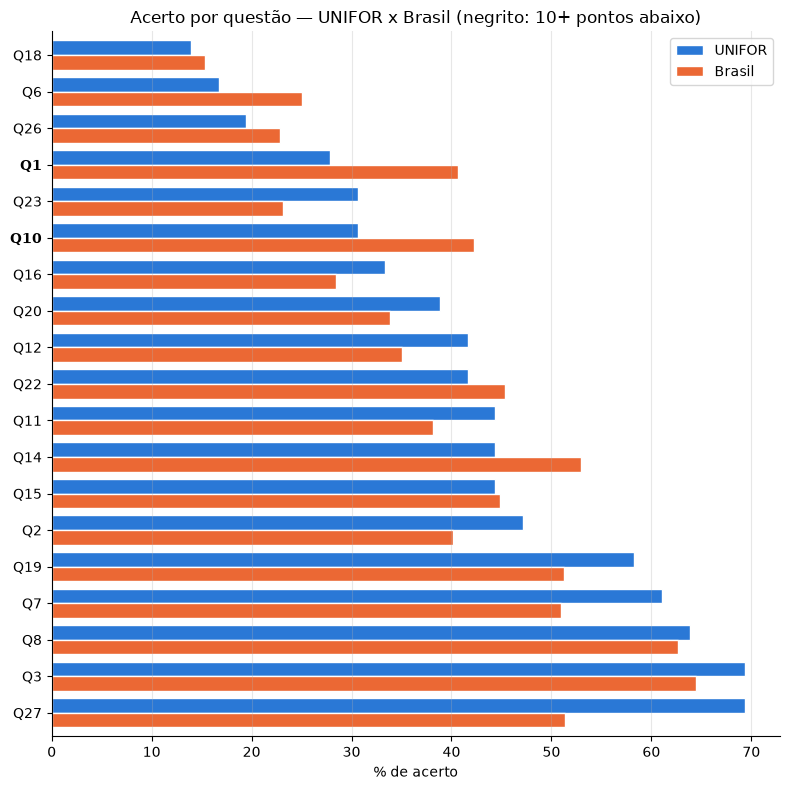

In [37]:
# Barras lado a lado, da questão com menos acerto na UNIFOR para a com mais
ax = comparacao[["UNIFOR", "Brasil"]].plot.barh(
    figsize=(8, 8), color=["#2a78d6", "#eb6834"], width=0.8, edgecolor="white", linewidth=1
)
for i, q in enumerate(comparacao.index):
    if q in abaixo.index:
        ax.get_yticklabels()[i].set_fontweight("bold")
ax.invert_yaxis()
ax.set_xlabel("% de acerto")
ax.set_ylabel("")
ax.set_title(f"Acerto por questão — UNIFOR x Brasil (negrito: {LIMITE_PONTOS}+ pontos abaixo)")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Conclusão

**A hipótese não se confirma.** O limite de 10 pontos é usado só como critério descritivo, para apontar questões que merecem atenção. Das 19 questões válidas do específico, 2 passam dele: Q1 (13,0 pontos abaixo do Brasil) e Q10 (11,7). Com o limite original de 15 pontos, nenhuma passaria.

Mesmo essas duas **não são estatisticamente significativas**: no teste binomial, p = 0,077 (Q1) e p = 0,104 (Q10), ambos acima de 0,05. Ou seja, com 36 alunos, diferenças desse tamanho podem acontecer só por acaso. Em 10 das 19 questões a UNIFOR acerta mais que o Brasil, com destaque para Q27 (18 pontos acima).

As questões em que os estudantes mais erram são difíceis para todo mundo, não só para a UNIFOR: Q18 (13,9% de acerto na UNIFOR, 15,3% no Brasil), Q6 (16,7% e 25,0%) e Q26 (19,4% e 22,8%).

A UNIFOR tem só 36 estudantes presentes, então cada aluno vale cerca de 2,8 pontos percentuais, e a margem de erro de um % de acerto chega a cerca de ±16 pontos.

**Temas:** os microdados não trazem o conteúdo de cada questão. Para ver se as questões destacadas se concentram em poucos temas, é preciso conferir cada uma na prova de Ciência da Computação 2021 do INEP (Q1 = 1ª objetiva do componente específico).